# Planner comparison: CEM, MPPI and GRASP

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/comparisons/planners.ipynb)

The same world model, three planners:
- **CEM** samples action sequences, keeps the best and refits a Gaussian to them;
- **MPPI** weights every sample by `exp(-cost / temperature)` instead of keeping a top set;
- **[GRASP](../planning/grasp.ipynb)** optimizes the plan by gradient descent through the model.

We vary how far each looks ahead and measure success, and the time each takes per step.

In [ ]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples]"

In [2]:
import torch
from torch.utils.data import DataLoader

from torch_world import evaluation, plots
from torch_world.datasets import TrajectoryDataset
from torch_world.envs import TwoRooms
from torch_world.models import LeWM
from torch_world.nn import CLSEncoder
from torch_world.planning import CEM, GRASP, MPPI
from torch_world.utils import fit

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

## One world model
A small LeWM learns PLDM's Two-Rooms from 1024 wandering episodes.

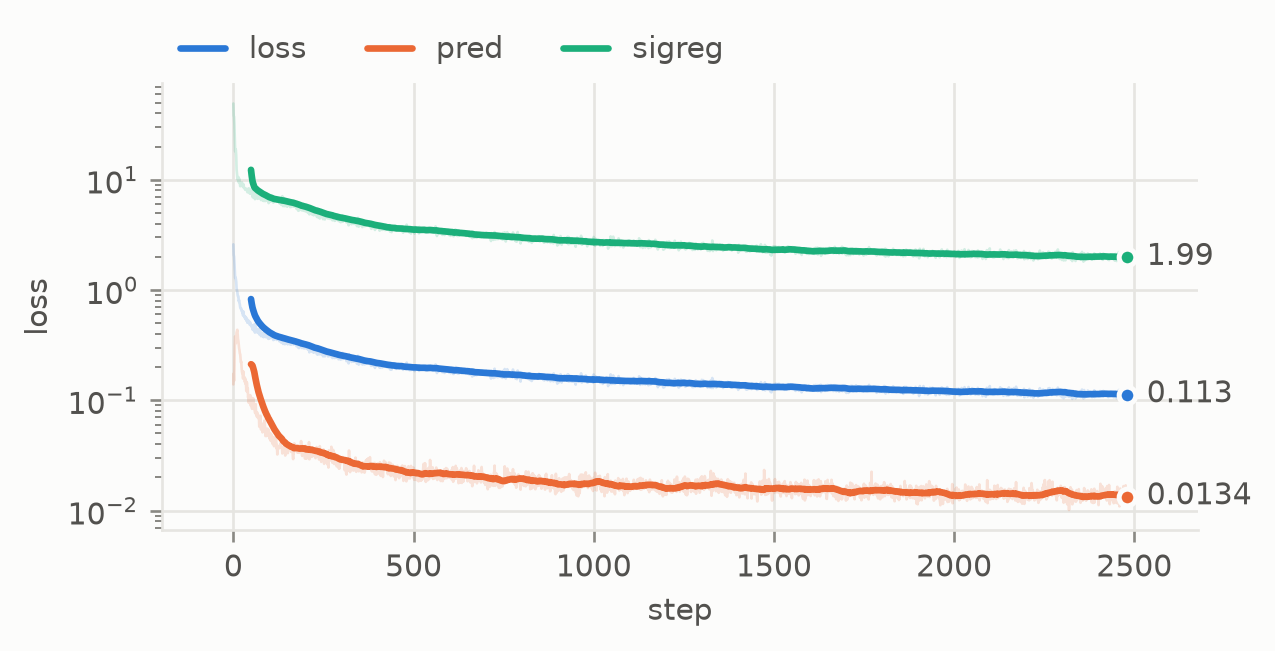

In [3]:
data = TwoRooms(batch_size=1024, device=device).collect(65, generator=torch.Generator().manual_seed(0))
loader = DataLoader(TrajectoryDataset(data, window=4), batch_size=128, shuffle=True, drop_last=True)
encoder = CLSEncoder(img_size=64, patch_size=8, embed_dim=128, depth=4, num_heads=4)
model = LeWM(encoder, action_dim=2, embed_dim=128, depth=4, num_heads=4, head_dim=32, mlp_dim=512, proj_dim=512, lamb=0.05).to(device)
log = fit(model, loader, epochs=5)
plots.curves(log, smooth=50)

## Planners at three horizons
Each planner gets about the same number of model calls per step (256 samples for CEM and MPPI, 300 gradient steps for GRASP) and replans after every step, on 64 tasks with the goal in the same room, 40 steps each.

In [4]:
def planners(horizon):
    return {
        "CEM": CEM(horizon=horizon, action_dim=2, num_samples=256, num_elites=32, iterations=6, bounds=(-1, 1)),
        "MPPI": MPPI(horizon=horizon, action_dim=2, num_samples=256, num_elites=32, num_pi_trajs=0, iterations=6, temperature=100),
        "GRASP": GRASP(horizon=horizon, action_dim=2, iterations=300, bounds=(-1, 1)),
    }


env = TwoRooms(batch_size=64, device=device)
start, goal = env.tasks(torch.Generator().manual_seed(1), same_room=True)
results = {}
for horizon in (3, 8, 16):
    policies = {name: evaluation.goal_policy(model, p, env.render(goal)) for name, p in planners(horizon).items()}
    results[f"horizon {horizon}"] = evaluation.goal_reaching(env, policies, start, goal, steps=40, success="reached")
    print(f"== horizon {horizon}\n{results[f'horizon {horizon}']}")

== horizon 3
                 success  reached   steps  final distance  progress     SPL  smoothness  ms / step
CEM       61% [49%, 72%]      61%    2.36           0.107     0.263   0.236       0.314   1.95e+03
MPPI      86% [75%, 92%]      86%    3.31          0.0905     0.639   0.101        1.25      1e+03
GRASP     50% [38%, 62%]      50%    1.25         0.00999     0.108   0.378       0.153   4.71e+04


== horizon 8
                 success  reached   steps  final distance  progress     SPL  smoothness  ms / step
CEM       70% [58%, 80%]      70%    9.62           0.133     0.513   0.277        0.35   5.83e+03
MPPI     98% [92%, 100%]      98%      10           0.168     0.436  0.0996        1.32    4.7e+03
GRASP     50% [38%, 62%]      50%    1.28           0.021     0.136   0.278       0.166   9.41e+03


== horizon 16
                 success  reached   steps  final distance  progress     SPL  smoothness  ms / step
CEM       62% [50%, 73%]      62%    12.1           0.141     0.505   0.189       0.349   1.21e+04
MPPI      89% [79%, 95%]      89%    13.5           0.206     0.269  0.0858        1.32   1.08e+04
GRASP     48% [37%, 60%]      48%    2.03            0.32    0.0294   0.175       0.263   1.22e+04


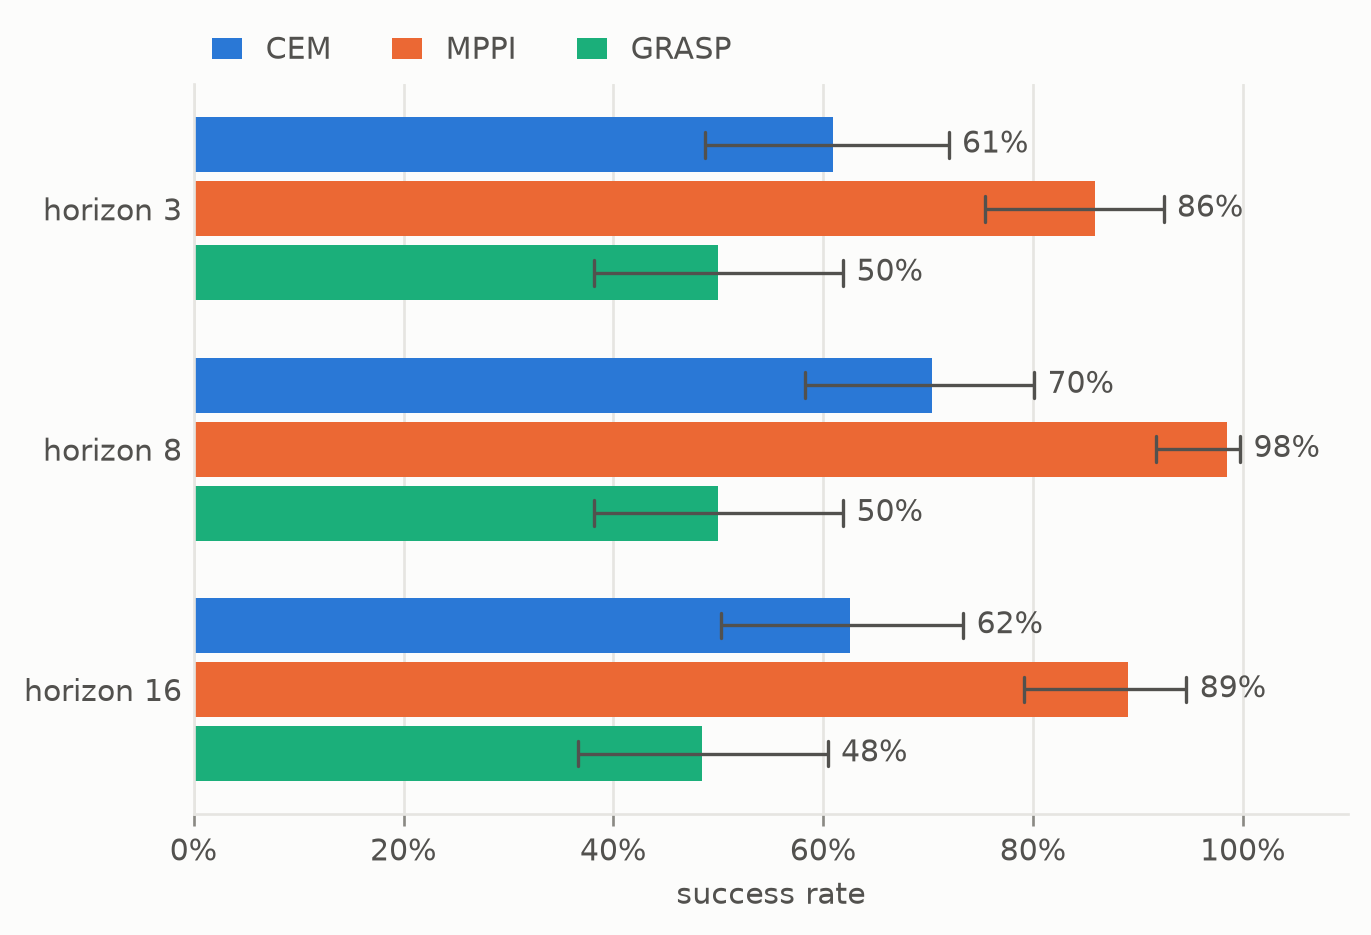

In [5]:
plots.bars({h: r.intervals() for h, r in results.items()}, xlabel="success rate")

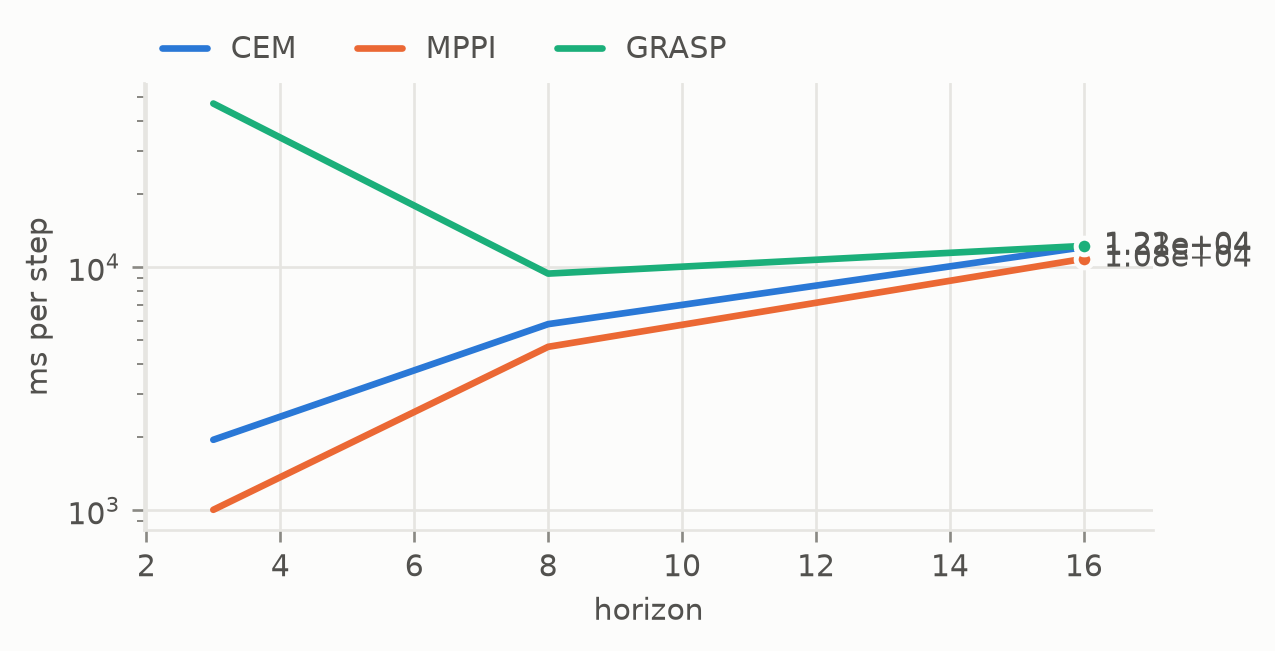

In [6]:
plots.curves(
    {name: ([3, 8, 16], [1000 * r.seconds[name] for r in results.values()]) for name in ("CEM", "MPPI", "GRASP")},
    smooth=1, xlabel="horizon", ylabel="ms per step",
)

## Summary
All three planners share one interface, `planner(model, z, goal)`, so they swap freely on any world model. The bars show how success changes as the horizon grows, and the curve how planning time grows with it.